# Master · Pemantauan Penyuntingan Wikipedia (Soal 1c: uji decoupling)
**Big Data** · dijalankan di **PC Master** (tempat broker Kafka dan producer berjalan)

Master membuat topic pendukung, memantau Worker dan **lag** consumer group `wiki-pekerja`, mengumpulkan hasil dari `wiki.hasil`,
lalu membuktikan: consumer melanjutkan dari offset terakhir, ada/tidaknya pesan **hilang** atau **ganda**, dan duplikat terbuang dengan kunci `(wiki, id)`.

**Urutan uji 1c**
1. Terminal: `python wiki_producer.py` (tanpa `--duration`, berjalan terus; hentikan dengan Ctrl+C di akhir).
2. Master: Sel 1 → 2, lalu **Sel 3 (monitor)** dibiarkan berjalan.
3. Worker 1 dan Worker 2: Sel 1 → 3. Tunggu sampai lag di monitor mendekati 0.
4. **Hentikan Sel 3 di KEDUA Worker** (Interrupt). Tunggu ±2 menit; lag di monitor naik terus. Ambil screenshot `kafka-consumer-groups` (perintah di Sel 4).
5. Jalankan lagi Sel 3 di kedua Worker. Lag turun kembali ke ±0.
6. Hentikan monitor (Interrupt), lalu jalankan Sel 4 → 6 untuk bukti dan grafik.

Hentikan **kedua** Worker. Jika hanya satu, Kafka memindahkan partisinya ke Worker lain (rebalance) dan yang teruji bukan decoupling.

## Sel 1. Konfigurasi dan topic pendukung

In [2]:
# ===== SEL 1: Konfigurasi dan topic pendukung =====
import os, sys, json, time, uuid
from pathlib import Path
from collections import Counter, defaultdict
from confluent_kafka import Consumer, KafkaError, TopicPartition
from confluent_kafka.admin import AdminClient, NewTopic

# ---------------- ISI SESUAI LINGKUNGAN ----------------
MASTER_IP = "192.168.1.15"          # kelompok: IP PC Master
N_WORKER  = 4                    # solo: 2 | kelompok: 4
# -------------------------------------------------------

BOOTSTRAP    = f"{MASTER_IP}:9092"
TOPIC_RAW    = "wiki.recentchange.raw"
TOPIC_HASIL  = "wiki.hasil"
TOPIC_STATUS = "wiki.status"
GROUP_PEKERJA = "wiki-pekerja"
RUN_ID       = uuid.uuid4().hex[:6]
LAPORAN_DIR  = Path("laporan")
LAPORAN_DIR.mkdir(exist_ok=True)
RETENSI = {"retention.ms": "259200000"}             # 72 jam, sama dengan topic mentah

admin = AdminClient({"bootstrap.servers": BOOTSTRAP})
daftar = [NewTopic(TOPIC_HASIL,  num_partitions=3, replication_factor=1, config=RETENSI),
          NewTopic(TOPIC_STATUS, num_partitions=1, replication_factor=1, config=RETENSI)]
for nama, f in admin.create_topics(daftar).items():
    try:
        f.result(); print("Topic dibuat :", nama)
    except Exception as e:
        print("Dilewati     :", nama, "->", str(e)[:80])

for _ in range(10):
    meta = admin.list_topics(timeout=5)
    if all(t in meta.topics for t in (TOPIC_RAW, TOPIC_HASIL, TOPIC_STATUS)):
        break
    time.sleep(1)
for t in (TOPIC_RAW, TOPIC_HASIL, TOPIC_STATUS):
    print(f"{t:<24}", f"{len(meta.topics[t].partitions)} partisi" if t in meta.topics else "TIDAK ADA")
PARTISI_RAW = sorted(meta.topics[TOPIC_RAW].partitions)
print("RUN_ID:", RUN_ID)

Topic dibuat : wiki.hasil
Topic dibuat : wiki.status
wiki.recentchange.raw    4 partisi
wiki.hasil               3 partisi
wiki.status              1 partisi
RUN_ID: 381801


In [1]:
import sys; print(sys.executable)

C:\BigData\venv\Scripts\python.exe


## Sel 2. Consumer Master, pengamat lag, dan monitor

In [3]:
# ===== SEL 2: Consumer Master, pengamat lag, dan monitor =====
from IPython.display import clear_output

konsumen = Consumer({
    "bootstrap.servers": BOOTSTRAP,
    "group.id": f"wiki-master-{RUN_ID}",      # group baru tiap RUN -> membaca hasil dari awal
    "auto.offset.reset": "earliest",
    "enable.auto.commit": True,
})
konsumen.subscribe([TOPIC_HASIL, TOPIC_STATUS])

# Pengamat: memakai group.id wiki-pekerja HANYA untuk membaca offset ter-commit (tidak subscribe, tidak ikut group)
pengamat = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": GROUP_PEKERJA, "enable.auto.commit": False})

per_offset   = Counter()                  # (partisi, offset) -> berapa kali hasilnya diterima
pelaksana    = defaultdict(list)          # (partisi, offset) -> [(worker, batch)]
per_event    = Counter()                  # (wiki, id) -> berapa kali diterima
event_unik   = {}                         # (wiki, id) -> rekaman terakhir (duplikat tertimpa)
tidak_valid  = 0
worker_info  = {}                         # worker -> status terakhir
riwayat      = []                         # (waktu, worker, status, detail)
sampel_lag   = []                         # (waktu, {partisi: lag}, worker_aktif)
T0 = time.time()

def sedot(detik=2.0):
    global tidak_valid
    akhir = time.time() + detik
    while time.time() < akhir:
        for msg in konsumen.consume(num_messages=1000, timeout=0.5):
            if msg.error():
                if msg.error().code() != KafkaError._PARTITION_EOF:
                    print("Kafka:", msg.error())
                continue
            try:
                d = json.loads(msg.value())
            except ValueError:
                continue
            if msg.topic() == TOPIC_HASIL:
                k = (d["partition"], d["offset"])
                per_offset[k] += 1
                pelaksana[k].append((d.get("worker"), d.get("batch")))
                if d.get("valid"):
                    e = (d["wiki"], d["id"])
                    per_event[e] += 1
                    event_unik[e] = d
                else:
                    tidak_valid += 1
            else:
                w = d.get("worker")
                info = worker_info.setdefault(w, {})
                info["terakhir"] = time.time()
                info["status"] = d["status"]
                if d["status"] == "SIAP":
                    info["partisi"] = d.get("partisi")
                if d["status"] in ("SIAP", "BERHENTI", "BATCH"):
                    info["pesan"] = d.get("pesan", info.get("pesan"))
                if d["status"] in ("SIAP", "BERHENTI"):
                    riwayat.append((d["waktu"], w, d["status"], d.get("offset_mulai") or d.get("alasan")))

def sedot_habis(diam=3.0):
    """Baca terus sampai tidak ada hasil baru selama `diam` detik (Master sudah mengejar)."""
    while True:
        n = sum(per_offset.values()) + len(riwayat)
        sedot(diam)
        if sum(per_offset.values()) + len(riwayat) == n:
            return

def offset_kafka():
    """(low, committed, high) per partisi topic mentah untuk group wiki-pekerja."""
    tps = [TopicPartition(TOPIC_RAW, p) for p in PARTISI_RAW]
    com = {tp.partition: tp.offset for tp in pengamat.committed(tps, timeout=10)}
    hasil = {}
    for p in PARTISI_RAW:
        lo, hi = pengamat.get_watermark_offsets(TopicPartition(TOPIC_RAW, p), timeout=10)
        c = com.get(p, -1)
        hasil[p] = (lo, c if c >= 0 else lo, hi)
    return hasil

def worker_aktif(batas=15):
    return sorted(w for w, i in worker_info.items()
                  if i.get("status") != "BERHENTI" and time.time() - i.get("terakhir", 0) < batas)

def monitor(jeda=3):
    """Tampilkan status Worker, lag per partisi, dan jumlah hasil. Interrupt untuk berhenti."""
    try:
        while True:
            sedot(jeda)
            ok = offset_kafka()
            lag = {p: hi - c for p, (lo, c, hi) in ok.items()}
            aktif = worker_aktif()
            sampel_lag.append((time.time(), lag, len(aktif)))
            clear_output(wait=True)
            print(f"MONITOR {time.strftime('%H:%M:%S')} | RUN {RUN_ID} | Worker aktif {len(aktif)}/{N_WORKER}: {aktif}")
            print("-" * 78)
            print(f"{'WORKER':<26}{'STATUS':<11}{'PARTISI':<12}{'DETIK LALU':>11}")
            for w, i in sorted(worker_info.items()):
                print(f"{w:<26}{i.get('status', '-'):<11}{str(i.get('partisi', '-')):<12}"
                      f"{time.time() - i.get('terakhir', 0):>11.0f}")
            print("-" * 78)
            print(f"{'PARTISI':<9}{'OFFSET AKHIR':>14}{'TER-COMMIT':>12}{'LAG':>8}")
            for p, (lo, c, hi) in ok.items():
                print(f"{p:<9}{hi:>14,}{c:>12,}{hi - c:>8,}")
            print(f"{'TOTAL':<9}{sum(v[2] for v in ok.values()):>14,}{sum(v[1] for v in ok.values()):>12,}{sum(lag.values()):>8,}")
            print("-" * 78)
            print(f"Hasil diterima: {sum(per_offset.values()):,} | offset unik: {len(per_offset):,} | "
                  f"event unik (wiki, id): {len(event_unik):,}")
            print("Interrupt (■) untuk menghentikan monitor.")
    except KeyboardInterrupt:
        print("Monitor dihentikan.")

print("Master siap. Jalankan Sel 3 untuk memantau.")

Master siap. Jalankan Sel 3 untuk memantau.


## Sel 3. Monitor (biarkan berjalan selama uji)

In [4]:
monitor()

MONITOR 13:27:43 | RUN 381801 | Worker aktif 4/4: ['NthaanSnn-w1', 'NthaanSnn-w2', 'NthaanSnn-w3', 'NthaanSnn-w4']
------------------------------------------------------------------------------
WORKER                    STATUS     PARTISI      DETIK LALU
NthaanSnn-w1              HIDUP      [2]                   2
NthaanSnn-w2              BATCH      [0]                   0
NthaanSnn-w3              HIDUP      [1]                   1
NthaanSnn-w4              HIDUP      [3]                   1
------------------------------------------------------------------------------
PARTISI    OFFSET AKHIR  TER-COMMIT     LAG
0                15,130      15,122       8
1                15,326      15,122     204
2                15,305      15,086     219
3                14,961      14,952       9
TOTAL            60,722      60,282     440
------------------------------------------------------------------------------
Hasil diterima: 62,272 | offset unik: 60,282 | event unik (wiki, id): 60,282
In

## Sel 4. Bukti offset dari Kafka
Jalankan perintah ini di **cmd** saat Worker dihentikan dan setelah Worker dijalankan lagi (screenshot keduanya):

```bat
C:\kafka\bin\windows\kafka-consumer-groups.bat --bootstrap-server 127.0.0.1:9092 --describe --group wiki-pekerja
```
Saat Worker berhenti: kolom `CONSUMER-ID` kosong, `CURRENT-OFFSET` tetap, `LOG-END-OFFSET` dan `LAG` naik.
Setelah Worker hidup lagi: `CURRENT-OFFSET` mengejar `LOG-END-OFFSET`, `LAG` kembali ±0.

Sel di bawah menampilkan hal yang sama dari Python, ditambah riwayat Worker berhenti dan melanjutkan.

In [5]:
# ===== SEL 4: Offset ter-commit dan riwayat berhenti/lanjut =====
sedot_habis()
ok = offset_kafka()
print(f"{'PARTISI':<9}{'AWAL':>8}{'TER-COMMIT':>12}{'AKHIR':>10}{'LAG':>8}")
for p, (lo, c, hi) in ok.items():
    print(f"{p:<9}{lo:>8,}{c:>12,}{hi:>10,}{hi - c:>8,}")

print("\nRiwayat Worker (SIAP = mulai/lanjut, beserta offset ter-commit tempat ia melanjutkan):")
for t, w, s, det in sorted(riwayat):
    print(f"  {time.strftime('%H:%M:%S', time.localtime(t))}  {w:<24} {s:<9} {det}")

PARTISI      AWAL  TER-COMMIT     AKHIR     LAG
0               0      15,170    15,216      46
1               0      15,390    15,405      15
2               0      15,349    15,386      37
3               0      14,999    15,053      54

Riwayat Worker (SIAP = mulai/lanjut, beserta offset ter-commit tempat ia melanjutkan):
  12:49:40  NthaanSnn-w1             SIAP      {'2': 'awal topic', '3': 'awal topic'}
  12:49:40  NthaanSnn-w2             SIAP      {'0': 'awal topic', '1': 'awal topic'}
  12:51:13  NthaanSnn-w2             BERHENTI  Interrupt
  12:51:13  NthaanSnn-w1             SIAP      {'2': 4975, '3': 4877}
  12:51:13  NthaanSnn-w3             SIAP      {'0': 4777, '1': 4795}
  12:51:37  NthaanSnn-w1             SIAP      {'3': 4983}
  12:51:37  NthaanSnn-w3             SIAP      {'0': 4969, '1': 4938}
  12:51:37  NthaanSnn-w2             SIAP      {'2': 5080}
  13:01:06  NthaanSnn-w3             SIAP      {'1': 7854}
  13:01:06  NthaanSnn-w4             SIAP      {'0': 766

## Sel 5. Analisis: pesan hilang, pesan ganda, dan deduplikasi
**Hilang** = offset yang sudah di-commit Worker tetapi hasilnya tidak pernah sampai ke Master.
**Ganda** = offset yang hasilnya diterima lebih dari sekali (pemrosesan ulang at-least-once).

In [6]:
# ===== SEL 5: Analisis hilang / ganda / dedup =====
sedot_habis()
ok = offset_kafka()
baris, total_hilang, total_ganda_off = [], 0, 0
for p, (lo, c, hi) in ok.items():
    diharapkan = range(lo, c)                                   # semua offset yang sudah di-commit
    diterima = {o for (pp, o) in per_offset if pp == p}
    hilang = [o for o in diharapkan if o not in diterima]
    ganda = sorted(o for (pp, o), n in per_offset.items() if pp == p and n > 1)
    total_hilang += len(hilang); total_ganda_off += len(ganda)
    baris.append((p, lo, c, len(diterima), len(hilang), len(ganda), hilang[:5]))

print(f"{'PARTISI':<8}{'AWAL':>7}{'COMMIT':>9}{'DITERIMA':>10}{'HILANG':>8}{'GANDA':>7}  contoh hilang")
for p, lo, c, n, h, g, contoh in baris:
    print(f"{p:<8}{lo:>7,}{c:>9,}{n:>10,}{h:>8,}{g:>7,}  {contoh}")

total_terima = sum(per_offset.values())
ganda_event = {e: n for e, n in per_event.items() if n > 1}
print("\n===== RINGKASAN BUKTI 1c =====")
print(f"Rekaman hasil diterima Master   : {total_terima:,}")
print(f"Offset unik                     : {len(per_offset):,}")
print(f"Pesan HILANG                    : {total_hilang:,}")
print(f"Offset diproses lebih dari sekali: {total_ganda_off:,} (kelebihan {total_terima - len(per_offset):,} rekaman)")
print(f"Event unik setelah dedup (wiki, id): {len(event_unik):,}")
print(f"Event dengan (wiki, id) ganda   : {len(ganda_event):,} -> {sum(ganda_event.values()) - len(ganda_event):,} rekaman dibuang")
print(f"Rekaman tidak valid             : {tidak_valid:,}")

contoh = [(k, v) for k, v in pelaksana.items() if len(v) > 1][:5]
if contoh:
    print("\nContoh offset yang diproses ulang (partisi, offset) -> [(worker, batch)]:")
    for k, v in contoh:
        print(" ", k, "->", v)

PARTISI    AWAL   COMMIT  DITERIMA  HILANG  GANDA  contoh hilang
0             0   15,337    15,337       0    452  []
1             0   15,539    15,539       0    469  []
2             0   15,528    15,528       0    449  []
3             0   15,135    15,135       0    492  []

===== RINGKASAN BUKTI 1c =====
Rekaman hasil diterima Master   : 63,529
Offset unik                     : 61,539
Pesan HILANG                    : 0
Offset diproses lebih dari sekali: 1,862 (kelebihan 1,990 rekaman)
Event unik setelah dedup (wiki, id): 61,539
Event dengan (wiki, id) ganda   : 1,862 -> 1,990 rekaman dibuang
Rekaman tidak valid             : 0

Contoh offset yang diproses ulang (partisi, offset) -> [(worker, batch)]:
  (0, 4777) -> [('NthaanSnn-w2', 'NthaanSnn-w2-11'), ('NthaanSnn-w3', 'NthaanSnn-w3-1')]
  (0, 4778) -> [('NthaanSnn-w2', 'NthaanSnn-w2-11'), ('NthaanSnn-w3', 'NthaanSnn-w3-1')]
  (0, 4780) -> [('NthaanSnn-w2', 'NthaanSnn-w2-11'), ('NthaanSnn-w3', 'NthaanSnn-w3-1')]
  (1, 4798) -> 

## Sel 6. Grafik lag selama uji
Bagian berwarna = periode **tidak ada Worker aktif**. Lag naik selama jeda (producer tetap menulis ke Kafka) lalu turun setelah Worker melanjutkan.

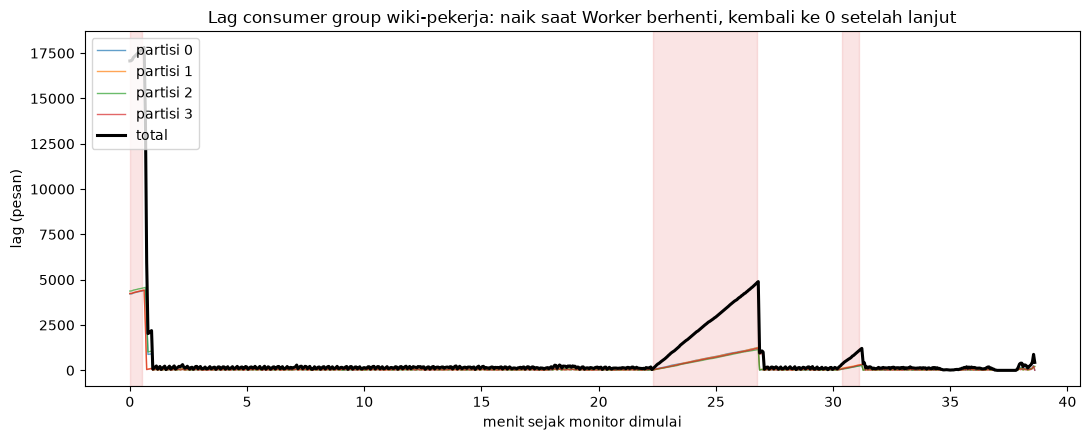

Disimpan: laporan\1c_lag_381801.png


In [7]:
# ===== SEL 6: Grafik lag consumer group selama uji =====
import matplotlib.pyplot as plt

if not sampel_lag:
    print("Belum ada sampel. Jalankan Sel 3 (monitor) selama uji.")
else:
    t = [(s[0] - sampel_lag[0][0]) / 60 for s in sampel_lag]
    fig, ax = plt.subplots(figsize=(11, 4.5))
    for p in PARTISI_RAW:
        ax.plot(t, [s[1][p] for s in sampel_lag], lw=1, alpha=0.7, label=f"partisi {p}")
    ax.plot(t, [sum(s[1].values()) for s in sampel_lag], lw=2.2, color="black", label="total")
    mulai = None
    for ti, s in zip(t, sampel_lag):
        if s[2] == 0 and mulai is None:
            mulai = ti
        elif s[2] > 0 and mulai is not None:
            ax.axvspan(mulai, ti, color="tab:red", alpha=0.12); mulai = None
    if mulai is not None:
        ax.axvspan(mulai, t[-1], color="tab:red", alpha=0.12)
    ax.set(title="Lag consumer group wiki-pekerja: naik saat Worker berhenti, kembali ke 0 setelah lanjut",
           xlabel="menit sejak monitor dimulai", ylabel="lag (pesan)")
    ax.legend(loc="upper left")
    fig.tight_layout()
    p = LAPORAN_DIR / f"1c_lag_{RUN_ID}.png"
    fig.savefig(p, dpi=120)
    plt.show()
    print("Disimpan:", p)